In [1]:
import geoai

In [2]:
train_raster_url = ("https://data.source.coop/opengeos/geoai/naip_rgb_train.tif")
train_vector_url = "https://data.source.coop/opengeos/geoai/naip_train_buildings.geojson"
test_raster_url = ("https://data.source.coop/opengeos/geoai/naip_test.tif")

In [3]:
train_raster = geoai.download_file(train_raster_url)
train_vector = geoai.download_file(train_vector_url)
test_raster = geoai.download_file(test_raster_url)

===== RASTER INFORMATION: naip_rgb_train.tif =====
Driver: GTiff
Dimensions: 2503 x 1126 pixels
Number of bands: 3
Data type: uint8
Coordinate Reference System: EPSG:26911
Georeferenced Bounds: BoundingBox(left=454780.8, bottom=5277567.0, right=456282.6, top=5278242.6)
Pixel Resolution: 0.6, 0.6
NoData Value: None
----- Band Statistics -----
Band 1:
  Min: 12.00
  Max: 251.00
  Mean: 150.67
  Std Dev: 48.02
Band 2:
  Min: 49.00
  Max: 251.00
  Mean: 141.92
  Std Dev: 43.47
Band 3:
  Min: 53.00
  Max: 251.00
  Mean: 120.90
  Std Dev: 41.78


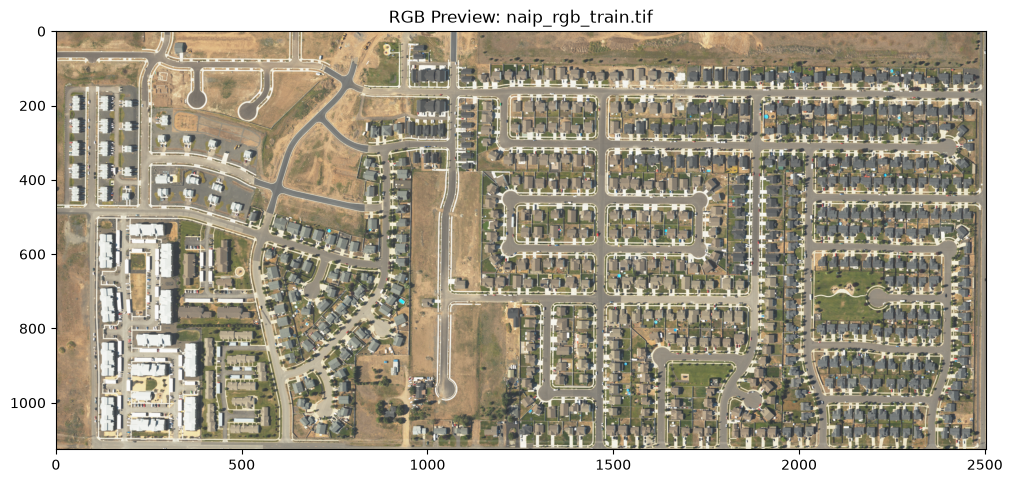

In [4]:
geoai.print_raster_info(train_raster, show_preview=True, figsize=(12,8),)

In [5]:
geoai.view_vector_interactive(vector_data=train_vector, tiles=train_raster)

In [6]:
geoai.view_raster(test_raster)

In [7]:
output_folder = "buildings"

tile = geoai.export_geotiff_tiles(
    in_raster=train_raster,
    out_folder="buildings",
    in_class_data=train_vector,
    tile_size=512,
    stride=256,
    buffer_radius=0
)

Generating tiles:   0%|          | 0/36 [00:00<?, ?it/s]

In [8]:
geoai.train_segmentation_model(
    images_dir= "buildings/images",
    labels_dir= "buildings/labels",
    output_dir= "buildings/unnet",
    architecture= "unet",
    encoder_name="resnet34",
    encoder_weights="imagenet",
    num_channels=3,
    num_classes=2,
    batch_size=8,
    num_epochs=20,
    learning_rate=0.001,
    val_split=0.2
)

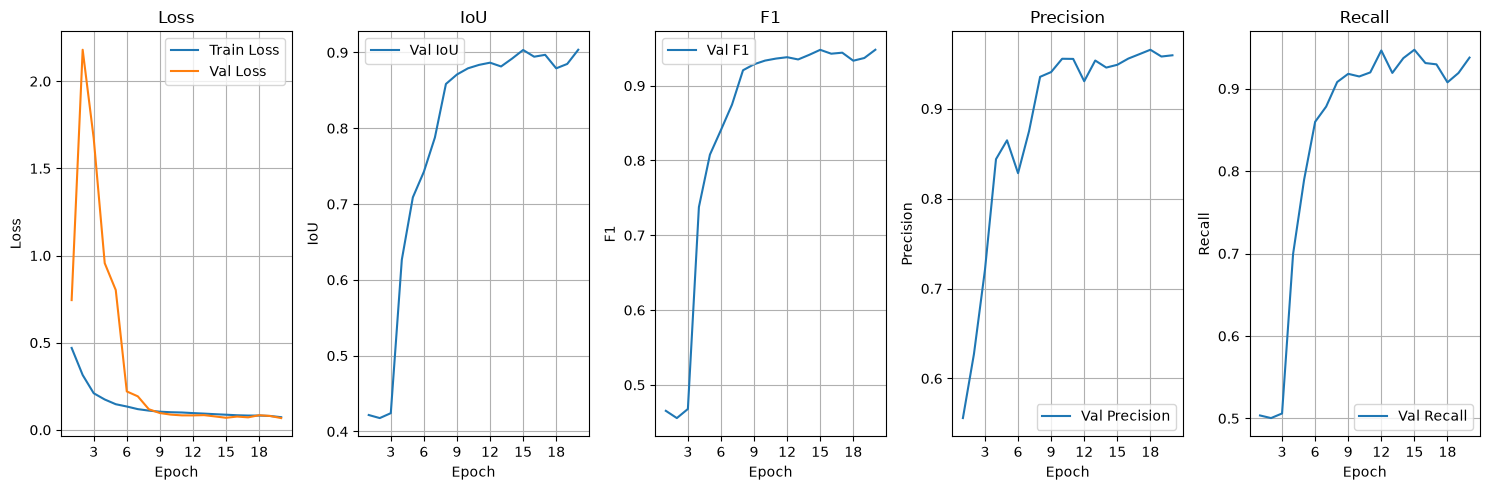

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.470027,0.744361,0.421737,0.465339,0.555940,0.503580
1,2,0.314647,2.180342,0.417684,0.455633,0.627109,0.500399
2,3,0.210180,1.672811,0.424165,0.467798,0.720767,0.505999
3,4,0.174285,0.956175,0.626541,0.737766,0.843838,0.699429
4,5,0.147168,0.802003,0.708806,0.807829,0.864806,0.789612
5,6,0.134025,0.220559,0.742602,0.840782,0.828266,0.859752
6,7,0.118955,0.192390,0.787777,0.874634,0.875099,0.878229
7,8,0.110483,0.118346,0.858420,0.920635,0.935407,0.908015
8,9,0.104293,0.096591,0.870906,0.928615,0.940705,0.917954
9,10,0.101188,0.087458,0.879067,0.933550,0.955496,0.914755


In [9]:
geoai.plot_performance_metrics(history_path="buildings/unnet/training_history.pth", figsize=(15,5))

In [10]:
masks_path = "naip_buildings_prediction.tif"
probability_path = "naip_test_probability_map.tif"
model_path = "buildings/unnet/best_model.pth"

In [11]:
geoai.semantic_segmentation(
    input_path=test_raster,
    output_path=masks_path,
    model_path=model_path,
    architecture="unet",
    encoder_name="resnet34",
    num_channels=3,
    num_classes=2,
    window_size=512,
    overlap=256,
    batch_size=4,
    probability_path=probability_path
)

  0%|          | 0/65 [00:00<?, ?it/s]

In [12]:
geoai.view_raster(
    masks_path,
    nodata=0,
    colormap="binary",
    basemap=test_raster
)

In [13]:
geoai.view_raster(probability_path, indexes=[2], basemap=test_raster)

In [14]:
# !pip install opencv-python

In [15]:
import sys
print(sys.executable)

!conda list | findstr /I "opencv numpy"
!pip show opencv-python opencv-contrib-python opencv-python-headless

C:\Users\DELL\miniconda3\envs\geoai\python.exe
libopencv                               4.13.0              headless_py313h6f7166e_8        conda-forge
numpy                                   2.5.3               py313ha8dc839_0                 conda-forge
opencv                                  4.13.0              headless_py313h9947189_8        conda-forge
py-opencv                               4.13.0              headless_py313h8155cb9_8        conda-forge
Name: opencv-python
Version: 4.13.0
Summary: 
Home-page: 
Author: 
Author-email: 
License: 
Location: C:\Users\DELL\miniconda3\envs\geoai\Lib\site-packages
Requires: 
Required-by: 
---
Name: opencv-python-headless
Version: 4.13.0
Summary: 
Home-page: 
Author: 
Author-email: 
License: 
Location: C:\Users\DELL\miniconda3\envs\geoai\Lib\site-packages
Requires: 
Required-by: albumentations, geoai-py, qudida, segment-geospatial


<Axes: >

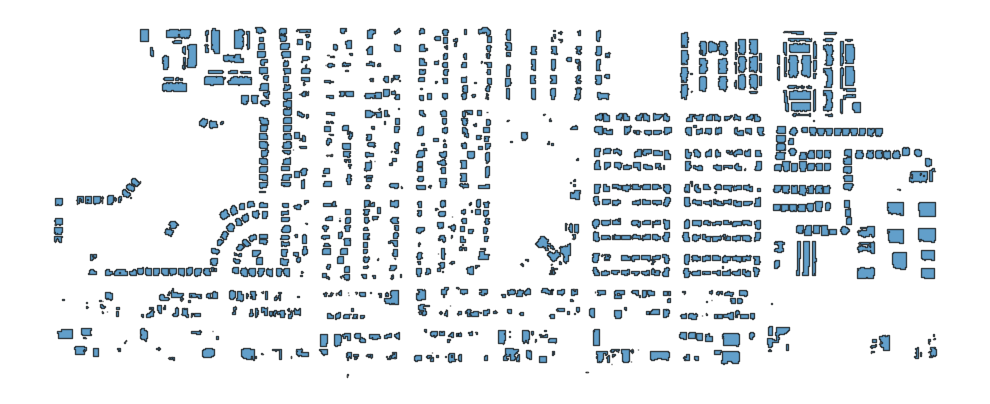

In [26]:
gdf = geoai.download_file('naip_buildings_prediction_2.geojson')
geoai.view_vector(gdf)

In [27]:
gdf_props = geoai.add_geometric_properties(gdf, area_unit="m2", length_unit="m")

In [28]:
geoai.view_vector_interactive(gdf_props, column="area_m2", tiles=test_raster)

In [33]:
gdf_filtered = gdf_props[(gdf_props['area_m2'] > 10)]
geoai.view_vector_interactive(gdf_filtered, column="area_m2", tiles=test_raster)

In [34]:
geoai.create_split_map(
    left_layer=gdf_filtered, 
    right_layer=test_raster, 
    left_args={
    "style":{"color":"red", "fillOpacity":0.2}
    },
    basemap=test_raster)

Map(center=[47.6464815, -117.59043750000001], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom…

In [35]:
geoai.empty_cache()